In [1]:
import pandas as pd

In [2]:
df = pd.read_parquet('./data/sms_training_data.parquet')

In [3]:
df.head(10)

,sms_message,label,embedding,cluster_label
0,"Go until jurong point, crazy.. Available only ...",0,"[0.0323555, 0.016009413, 0.06194499, -0.042135...",0
1,Ok lar... Joking wif u oni...,0,"[0.08206976, -0.018639985, 0.026879955, -0.093...",0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,"[0.094782084, -0.01949946, 0.01407177, -0.0518...",1
3,U dun say so early hor... U c already then say...,0,"[0.07993865, -0.022020226, 0.020707738, -0.054...",0
4,"Nah I don't think he goes to usf, he lives aro...",0,"[0.06651712, 0.044909604, 0.010687282, -0.0353...",0
5,FreeMsg Hey there darling it's been 3 week's n...,1,"[0.056607906, -0.021531032, -0.012310791, -0.0...",0
6,Even my brother is not like to speak with me. ...,0,"[0.007443019, 0.07728682, 0.020719808, -0.1012...",0
7,As per your request 'Melle Melle (Oru Minnamin...,0,"[0.03562765, -0.022721196, 0.017454114, -0.036...",1
8,WINNER!! As a valued network customer you have...,1,"[0.058819037, -0.0017373714, 0.03937096, -0.01...",1
9,Had your mobile 11 months or more? U R entitle...,1,"[0.0233127, -0.005538072, -0.022738425, -0.010...",1


In [4]:
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 0

# The embedding column is the input, label the ground truth; sms_message and
# cluster_label play no part in training.
X = np.stack(df['embedding'].to_numpy())  # (n, 1024) float32
y = df['label'].to_numpy(dtype=np.float32)  # float targets for BCEWithLogitsLoss

# 70 / 15 / 15, in two stratified cuts. Spam is only ~13% of the rows, so an
# unstratified split can hand validation and test a class mix that differs
# noticeably from train's and make the scores hard to read.
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for name, split in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(f'{name:<5} {len(split):>5} rows  spam {split.mean():.3f} '
          f'({int(split.sum())})')

train  3900 rows  spam 0.134 (523)
val     836 rows  spam 0.134 (112)
test    836 rows  spam 0.134 (112)


In [5]:
import torch
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 64


def make_dataset(features, labels):
    # Labels come out as (n, 1) to line up with the single-logit head the
    # classifier will end in.
    return TensorDataset(torch.from_numpy(features), torch.from_numpy(labels).unsqueeze(1))


train_ds = make_dataset(X_train, y_train)
validation_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

# Shuffle training batches only; val and test keep a fixed order so repeated
# evaluations are comparable.
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(validation_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

xb, yb = next(iter(train_loader))
print(f'batch  X {tuple(xb.shape)} {xb.dtype}  y {tuple(yb.shape)} {yb.dtype}')
print(
    f'rows   {len(train_ds)} + {len(validation_ds)} + {len(test_ds)} = 'f'{len(train_ds) + len(validation_ds) + len(test_ds)} of {len(df)}')

batch  X (64, 1024) torch.float32  y (64, 1) torch.float32
rows   3900 + 836 + 836 = 5572 of 5572


In [6]:
import torch.nn.functional as F

DROPOUT_RATE = 0.2


class BlueShiftNet(torch.nn.Module):
    def __init__(self):
        super(BlueShiftNet, self).__init__()
        self.fc1 = torch.nn.Linear(1024, 512)
        self.fc4 = torch.nn.Linear(512, 256)
        self.fc5 = torch.nn.Linear(256, 128)
        self.fc6 = torch.nn.Linear(128, 1)
        # Dropout holds no state, so one module can serve every hidden layer;
        # it follows the activation and never the output.
        self.dropout = torch.nn.Dropout(DROPOUT_RATE)

    def forward(self, x):
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.dropout(F.relu(self.fc4(x)))
        x = self.dropout(F.relu(self.fc5(x)))
        x = F.sigmoid(self.fc6(x))
        return x

model = BlueShiftNet()
model

BlueShiftNet(
  (fc1): Linear(in_features=1024, out_features=512, bias=True)
  (fc4): Linear(in_features=512, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=128, bias=True)
  (fc6): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)

In [7]:
import torch.optim as optim
import torch.nn as nn

# Hyperparameters
epochs = 5
learning_rate = 0.001

# Loss and optimizer
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)


def evaluate(loader):
    """Mean loss and accuracy over a loader, with the model in eval mode."""
    # eval() switches dropout off, so validation scores the full network, and
    # no_grad() keeps the pass out of the autograd graph.
    model.eval()
    total_loss, correct, seen = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            outputs = model(inputs)
            # Weight by batch size: the last batch is usually short.
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += ((outputs > 0.5).float() == labels).sum().item()
            seen += labels.size(0)
    return total_loss / seen, correct / seen


# Rebuilt here rather than at import, so re-running the cell restarts the
# record instead of appending a second run onto the first.
history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_accuracy': []}

# Training loop
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
    train_loss = running_loss / len(train_ds)
    # Validation runs every epoch: train loss alone can't tell learning from
    # memorising, and test stays untouched until the end.
    val_loss, val_acc = evaluate(validation_loader)

    history['epoch'].append(epoch + 1)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)

    print(f'Epoch {epoch + 1}/{epochs}, Loss: {train_loss:.4f}, '
          f'Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.2%}')

Epoch 1/5, Loss: 0.2323, Val Loss: 0.0488, Val Accuracy: 98.80%
Epoch 2/5, Loss: 0.0441, Val Loss: 0.0293, Val Accuracy: 99.28%
Epoch 3/5, Loss: 0.0274, Val Loss: 0.0391, Val Accuracy: 98.80%
Epoch 4/5, Loss: 0.0205, Val Loss: 0.0275, Val Accuracy: 99.16%
Epoch 5/5, Loss: 0.0141, Val Loss: 0.0256, Val Accuracy: 99.28%


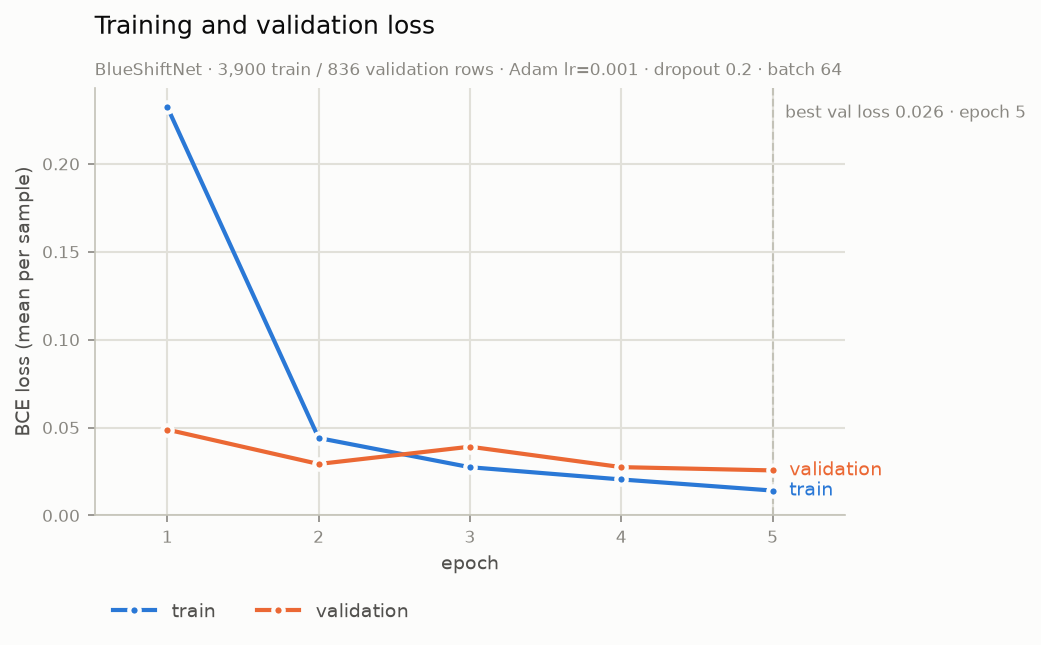

epoch,train_loss,val_loss,val_accuracy
1,0.2323,0.0488,98.80%
2,0.0441,0.0293,99.28%
3,0.0274,0.0391,98.80%
4,0.0205,0.0275,99.16%
5,0.0141,0.0256,99.28%


In [8]:
import matplotlib.pyplot as plt

hist_df = pd.DataFrame(history)

# Same surface and two-series hues as the clusters notebook, so the figures in
# this project read as one set. Both curves are BCE loss in the same units, so
# they share a single y-axis — a second scale would invent a comparison.
SURFACE, GRID, AXIS = '#fcfcfb', '#e1e0d9', '#c3c2b7'
INK, INK_2, MUTED = '#0b0b0b', '#52514e', '#898781'
SERIES = {'train': '#2a78d6', 'validation': '#eb6834'}

best = hist_df.loc[hist_df['val_loss'].idxmin()]

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

for name, column in (('train', 'train_loss'), ('validation', 'val_loss')):
    # 2px line, markers ringed in the surface colour so crossings stay readable
    ax.plot(hist_df['epoch'], hist_df[column], label=name, color=SERIES[name],
            linewidth=2, marker='o', markersize=5, markeredgewidth=2,
            markeredgecolor=SURFACE, zorder=3)
    # Direct label at the right-hand end: identity without a legend round-trip
    ax.annotate(name, (hist_df['epoch'].iloc[-1], hist_df[column].iloc[-1]),
                textcoords='offset points', xytext=(8, 0), va='center',
                fontsize=9, color=SERIES[name])

# Lowest validation loss — the epoch an early-stopping rule would have kept.
# Labelled at the top of the axes rather than beside the point, where it would
# land on whichever curve happens to pass through.
ax.axvline(best['epoch'], color=AXIS, linewidth=1, linestyle='--', zorder=1)
ax.annotate(f'best val loss {best["val_loss"]:.3f} · epoch {int(best["epoch"])}',
            (best['epoch'], 1), xycoords=('data', 'axes fraction'),
            textcoords='offset points', xytext=(6, -8), va='top',
            fontsize=8, color=MUTED)

ax.grid(True, color=GRID, linewidth=1, linestyle='-')
ax.set_axisbelow(True)
ax.margins(x=0.12)
ax.set_ylim(bottom=0)
ax.set_xticks(hist_df['epoch'])
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
for s in ('left', 'bottom'):
    ax.spines[s].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=8)

ax.set_xlabel('epoch', color=INK_2, fontsize=9)
ax.set_ylabel('BCE loss (mean per sample)', color=INK_2, fontsize=9)
ax.set_title('Training and validation loss', color=INK, fontsize=12,
             loc='left', pad=26)
ax.text(0, 1.03, f'BlueShiftNet · {len(train_ds):,} train / {len(validation_ds):,} '
                 f'validation rows · Adam lr={learning_rate} · dropout '
                 f'{DROPOUT_RATE} · batch {BATCH_SIZE}',
        transform=ax.transAxes, color=MUTED, fontsize=8)

# Legend below the plot: the curves already fill the panel, and both series
# carry a direct label, so it only has to back them up.
leg = ax.legend(title=None, frameon=False, ncols=2, loc='upper left',
                bbox_to_anchor=(0, -0.16))
for t in leg.get_texts():
    t.set_color(INK_2)
    t.set_fontsize(9)

fig.tight_layout()
plt.show()

# Table view: the same numbers as text, so nothing is readable only from the plot
hist_df.style.format({'train_loss': '{:.4f}', 'val_loss': '{:.4f}',
                      'val_accuracy': '{:.2%}'}).hide(axis='index')

In [9]:
print("Our model: \n\n", model, '\n')
print("The state dict keys: \n\n", model.state_dict().keys())

Our model: 

 BlueShiftNet(
  (fc1): Linear(in_features=1024, out_features=512, bias=True)
  (fc4): Linear(in_features=512, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=128, bias=True)
  (fc6): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
) 

The state dict keys: 

 odict_keys(['fc1.weight', 'fc1.bias', 'fc4.weight', 'fc4.bias', 'fc5.weight', 'fc5.bias', 'fc6.weight', 'fc6.bias'])


In [10]:
# Only plain data goes in the file — ints, and the tensors in the state dict.
# Storing the nn.Linear objects themselves would pickle live modules, which
# torch.load refuses to unpickle under its weights_only=True default.
checkpoint = {'input_size': model.fc1.in_features,
              'output_size': model.fc6.out_features,
              'hidden_layers': [model.fc1.out_features,
                                model.fc4.out_features,
                                model.fc5.out_features],
              'state_dict': model.state_dict()}

torch.save(checkpoint, 'checkpoint.pth')

In [11]:
def load_checkpoint(filepath):
    checkpoint = torch.load(filepath)
    # BlueShiftNet fixes its own layer sizes, so there is nothing to pass in;
    # the sizes in the file are a record of what was trained. load_state_dict
    # raises on a shape mismatch if the class has changed since the save.
    model = BlueShiftNet()
    model.load_state_dict(checkpoint['state_dict'])
    # A fresh module starts in train mode, which would leave dropout on for
    # anything the caller predicts with.
    model.eval()

    return model

In [12]:
model = load_checkpoint('checkpoint.pth')
print(model)

BlueShiftNet(
  (fc1): Linear(in_features=1024, out_features=512, bias=True)
  (fc4): Linear(in_features=512, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=128, bias=True)
  (fc6): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)


In [13]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)


def predict(net, loader):
    """Predicted probabilities and true labels for a loader, in eval mode."""
    net.eval()
    probs, targets = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            probs.append(net(inputs))
            targets.append(labels)
    return torch.cat(probs).numpy().ravel(), torch.cat(targets).numpy().ravel()


# model here is the one returned by load_checkpoint, and test has been held out
# of every decision so far — this is its first and only read.
y_prob, y_true = predict(model, test_loader)
y_pred = (y_prob > 0.5).astype(int)

# Precision, recall and F1 are for spam (label 1). Accuracy alone flatters a
# 7:1 split — always guessing ham already scores 86.6% on this test set.
print(f'Accuracy score: {accuracy_score(y_true, y_pred):.3f}')
print(f'Precision score: {precision_score(y_true, y_pred):.3f}')
print(f'Recall score: {recall_score(y_true, y_pred):.3f}')
print(f'F1 score: {f1_score(y_true, y_pred):.3f}')

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
print(f'\n{len(y_true):,} test messages — {tp} spam caught, {fn} missed, '
      f'{fp} ham wrongly flagged, {tn} ham cleared')

Accuracy score: 0.992
Precision score: 0.949
Recall score: 0.991
F1 score: 0.969

836 test messages — 111 spam caught, 1 missed, 6 ham wrongly flagged, 718 ham cleared


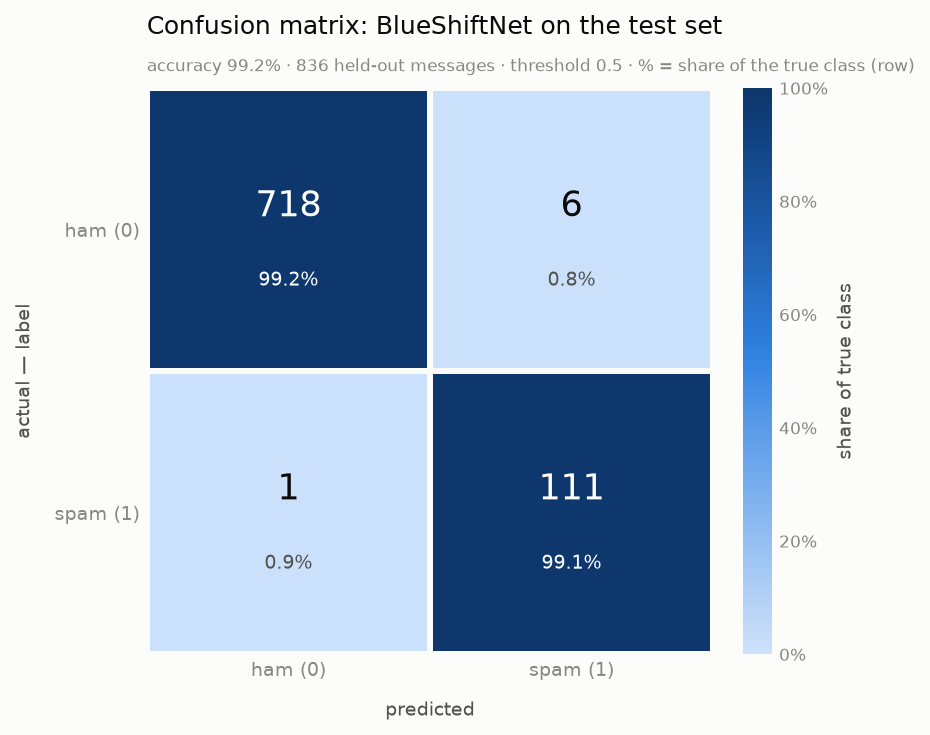

predicted,0,1,All
actual,,,
0,718,6,724
1,1,111,112
All,719,117,836


In [14]:
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap

CLASSES = ['ham (0)', 'spam (1)']

cm = confusion_matrix(y_true, y_pred)
# Row-normalise for colour: the classes are ~7:1 imbalanced, so raw counts would
# paint the ham row dark and both error cells the same near-white.
cm_share = cm / cm.sum(axis=1, keepdims=True)

# Magnitude on a grid -> sequential encoding: one hue, light to dark, never a
# rainbow. Same blue ramp (steps 100..700) as the clusters notebook.
BLUE_RAMP = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7',
             '#3987e5', '#2a78d6', '#256abf', '#1c5cab', '#184f95', '#104281',
             '#0d366b']
cmap = LinearSegmentedColormap.from_list('blue_sequential', BLUE_RAMP)

fig, ax = plt.subplots(figsize=(6.4, 5), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# edgecolor in the surface colour is the 2px gap between cells -- neighbours are
# separated by negative space, not by a border drawn around each one
mesh = ax.pcolormesh(np.arange(3), np.arange(3), cm_share, cmap=cmap,
                     vmin=0, vmax=1, edgecolors=SURFACE, linewidth=2)
ax.invert_yaxis()
ax.set_aspect('equal')

# Count + row share in each cell. Four cells, so the grid is its own table; ink
# or white is picked per cell from the fill's luminance so text always clears it.
for i in range(2):
    for j in range(2):
        r, g, b, _ = cmap(cm_share[i, j])
        light_fill = 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.55
        ax.text(j + 0.5, i + 0.42, f'{cm[i, j]:,}', ha='center', va='center',
                fontsize=17, color=INK if light_fill else '#ffffff')
        ax.text(j + 0.5, i + 0.68, f'{cm_share[i, j]:.1%}', ha='center',
                va='center', fontsize=9,
                color=INK_2 if light_fill else '#ffffff')

ax.set_xticks(np.arange(2) + 0.5, CLASSES)
ax.set_yticks(np.arange(2) + 0.5, CLASSES)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
for s in ax.spines.values():
    s.set_visible(False)

ax.set_xlabel('predicted', color=INK_2, fontsize=9, labelpad=10)
ax.set_ylabel('actual — label', color=INK_2, fontsize=9, labelpad=10)
ax.set_title('Confusion matrix: BlueShiftNet on the test set', color=INK,
             fontsize=12, loc='left', pad=26)
ax.text(0, 1.03, f'accuracy {accuracy_score(y_true, y_pred):.1%} · '
                 f'{len(y_true):,} held-out messages · threshold 0.5 · '
                 f'% = share of the true class (row)',
        transform=ax.transAxes, color=MUTED, fontsize=8)

# Scale legend for the continuous encoding
cb = fig.colorbar(mesh, ax=ax, fraction=0.045, pad=0.04)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=MUTED, labelsize=8, length=0)
cb.ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
cb.set_label('share of true class', color=INK_2, fontsize=9)

fig.tight_layout()
plt.show()

# Table view: the same numbers as text, so nothing is readable only from colour
pd.crosstab(y_true.astype(int), y_pred, rownames=['actual'],
            colnames=['predicted'], margins=True)

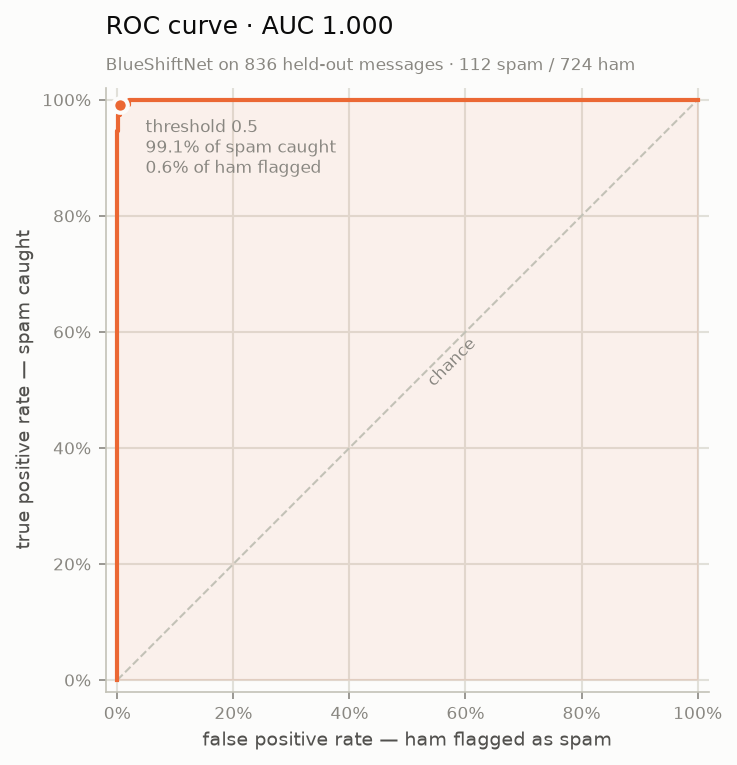

threshold,spam caught (TPR),ham flagged (FPR),spam missed,ham flagged
0.10,100.0%,2.2%,0,16
0.25,99.1%,1.2%,1,9
0.50,99.1%,0.8%,1,6
0.75,99.1%,0.6%,1,4
0.90,96.4%,0.1%,4,1


In [15]:
from sklearn.metrics import roc_auc_score, roc_curve

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc = roc_auc_score(y_true, y_prob)

# Where the 0.5 threshold used above sits on the curve
op = np.argmin(np.abs(thresholds - 0.5))

fig, ax = plt.subplots(figsize=(5.6, 5.2), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# Chance line first, in axis grey — it is a reference, not a second series
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1, linestyle='--', zorder=2)
ax.text(0.55, 0.5, 'chance', color=MUTED, fontsize=8, rotation=45,
        rotation_mode='anchor', ha='left', va='bottom')

# One series, so no legend box: the title names it
ax.plot(fpr, tpr, color=SERIES['validation'], linewidth=2, zorder=3)
ax.fill_between(fpr, tpr, color=SERIES['validation'], alpha=0.08, zorder=1)

ax.plot(fpr[op], tpr[op], marker='o', markersize=7, markeredgewidth=2,
        markeredgecolor=SURFACE, color=SERIES['validation'], zorder=4)
ax.annotate(f'threshold 0.5\n{tpr[op]:.1%} of spam caught\n'
            f'{fpr[op]:.1%} of ham flagged',
            (fpr[op], tpr[op]), textcoords='offset points', xytext=(12, -6),
            va='top', fontsize=8, color=MUTED)

ax.grid(True, color=GRID, linewidth=1, linestyle='-')
ax.set_axisbelow(True)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_aspect('equal')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
for s in ('left', 'bottom'):
    ax.spines[s].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=8)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

ax.set_xlabel('false positive rate — ham flagged as spam', color=INK_2,
              fontsize=9)
ax.set_ylabel('true positive rate — spam caught', color=INK_2, fontsize=9)
ax.set_title(f'ROC curve · AUC {auc:.3f}', color=INK, fontsize=12, loc='left',
             pad=26)
ax.text(0, 1.03, f'BlueShiftNet on {len(y_true):,} held-out messages · '
                 f'{int(y_true.sum())} spam / {int((1 - y_true).sum())} ham',
        transform=ax.transAxes, color=MUTED, fontsize=8)

fig.tight_layout()
plt.show()

# Table view: what the curve costs at a few thresholds, since the plot is read
# by eye but the threshold is chosen by number
rows = [{'threshold': t,
         'spam caught (TPR)': ((y_prob > t) & (y_true == 1)).sum() / (y_true == 1).sum(),
         'ham flagged (FPR)': ((y_prob > t) & (y_true == 0)).sum() / (y_true == 0).sum(),
         'spam missed': int(((y_prob <= t) & (y_true == 1)).sum()),
         'ham flagged': int(((y_prob > t) & (y_true == 0)).sum())}
        for t in (0.1, 0.25, 0.5, 0.75, 0.9)]
pd.DataFrame(rows).style.format({'threshold': '{:.2f}',
                                 'spam caught (TPR)': '{:.1%}',
                                 'ham flagged (FPR)': '{:.1%}'}).hide(axis='index')

Resume: Nueral Network trained on actual labels gives better result then custom Naive Bayes solution